# Лабораторная работа 1

Проваторов Роман Андреевич 409407 M3407

Выбрана тематика `Programming Languages`, представленная на arXiv категорией `cs.PL`

In [1]:
from __future__ import annotations
import itertools, math, re, time, unicodedata
from collections import Counter
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display

## Сбор данных

In [2]:
import xml.etree.ElementTree as ET
import requests
from datetime import datetime, timezone
from pathlib import Path

API_URL = 'https://export.arxiv.org/api/query'
CATEGORY = 'cs.PL'
MIN_DATE = '202001010000'
MAX_DATE = datetime.now(timezone.utc).strftime('%Y%m%d%H%M')
N_PUBLICATIONS, BATCH_SIZE = 1000, 100
ATOM = {'a': 'http://www.w3.org/2005/Atom', 'os': 'http://a9.com/-/spec/opensearch/1.1/'}

def parse_xml(content):
    root = ET.fromstring(content)
    records = []
    for entry in root.findall('a:entry', ATOM):
        authors = [x.findtext('a:name', namespaces=ATOM) for x in entry.findall('a:author', ATOM)]
        categories = [x.attrib.get('term', '') for x in entry.findall('a:category', ATOM)]
        url = entry.findtext('a:id', namespaces=ATOM)
        records.append({'arxiv_id': url.rsplit('/', 1)[-1],
                        'title': entry.findtext('a:title', namespaces=ATOM),
                        'authors': '; '.join(authors),
                        'abstract': entry.findtext('a:summary', namespaces=ATOM),
                        'published': entry.findtext('a:published', namespaces=ATOM),
                        'updated': entry.findtext('a:updated', namespaces=ATOM),
                        'categories': '; '.join(categories),
                        'url': url})
    return records

def download_arxiv(n=N_PUBLICATIONS, batch_size=BATCH_SIZE):
    session = requests.Session()
    rows = []
    for start in range(0, n, batch_size):
        query = f'cat:"{CATEGORY}" AND submittedDate:[{MIN_DATE} TO {MAX_DATE}]'
        params = {'search_query': query,
                  'start': start,
                  'max_results': min(batch_size, n-start),
                  'sortBy': 'submittedDate',
                  'sortOrder': 'descending'}

        for _ in range(4):
            try:
                response = session.get(API_URL, params=params, timeout=60)
                response.raise_for_status()
                page = parse_xml(response.content)
                if not page:
                    time.sleep(2)
                    continue
                rows.extend(page)
                print(f'Получено {len(rows):>3}/{n} записей')
                break
            except Exception as exc:
                print(f'Ошибка при скачивании данных для запроса: {query} и записей {start}-{start+batch_size}: {exc}')
                time.sleep(2)

    return pd.DataFrame(rows).drop_duplicates('arxiv_id').head(n)


if Path('arxiv_data.csv').exists():
    df = pd.read_csv('arxiv_data.csv', encoding='utf-8-sig')
else:
    df = download_arxiv()
    df.to_csv('arxiv_data.csv', index=False, encoding='utf-8-sig')

df['published'] = pd.to_datetime(df['published'], utc=True)
df['updated'] = pd.to_datetime(df['updated'], utc=True)
df['year'] = df['published'].dt.year

display(df[['arxiv_id', 'published', 'title', 'authors', 'abstract']].head(10))

,arxiv_id,published,title,authors,abstract
0,2610.01246v1,2026-10-01 07:42:47+00:00,Augmenting Rewrite Rule Sets via Knuth-Bendix ...,Michael Schifferer; Marcel Ullrich; Sebastian ...,Equality Saturation (EqSat) is a powerful tech...
1,2610.01198v1,2026-10-01 07:10:43+00:00,Associativity and Commutativity in Equality Sa...,Tarik Rosin; Marcel Ullrich; Sebastian Hack,Equality saturation is a promising technique f...
2,2610.00530v1,2026-09-30 18:16:21+00:00,Fixing the Fixpoint: A Formal Theory of Conver...,Chengxi Yang; Tej Chajed; Thomas Reps,Modern incremental computation theories like D...
3,2609.40119v1,2026-09-30 16:44:34+00:00,Automatically Building Machine-Checked Assuran...,Haokun Li; Zhongyi Wang; Guanyan Li; Xiao Yi; ...,Large language models (LLMs) have shown promis...
4,2609.40046v1,2026-09-30 16:14:11+00:00,Freely Generated Categorical Structures and Au...,Fernando Lucatelli Nunes,This version contains the introduction and con...
5,2609.39022v2,2026-09-30 05:27:26+00:00,From Verification Failures to Reusable Guidanc...,Yuqing Zhai; Xiaohong Chen; Lingming Zhang; Sr...,Coding agents need to establish that a program...
6,2609.38981v1,2026-09-30 04:58:09+00:00,"Vosti: Specifying, Implementing, and Verifying...",Jianxing Qin; Alexander Du; Danfeng Zhang; Mat...,LLM inference systems may vary batch compositi...
7,2609.38497v1,2026-09-29 20:22:13+00:00,The Mode of Null-A: Compositional Computation ...,Barak A. Pearlmutter; Jeffrey Mark Siskind,We present a novel algorithm for calculating t...
8,2609.38439v1,2026-09-29 19:31:43+00:00,Automated Prefetching for Object Spatial Progr...,Baichuan Li; Jayanaka Dantanarayana; Savini Ka...,Dependent database accesses can serialize appl...
9,2609.37728v1,2026-09-29 14:50:33+00:00,Formal Reasoning about Performance Models,Moussa Labbadi; Rupak Majumdar; V. R. Sathiyan...,Discrete-event simulation is a standard techni...


## Разведочный анализ

,Значение
Публикаций,1000
Период,2026-01-22 — 2026-10-01
Уникальных авторов,3057
Медиана слов в названии,8.0
Медиана слов в аннотации,177.5
Дубликатов arXiv ID,0
Дубликатов названий,0
Пустых названий,0
Пустых аннотаций,0
Пустых авторов,0


,Публикаций
Автор,
Peisen Yao,9
Joseph Tassarotti,8
Alexandra Silva,6
Ehud Shapiro,6
Kevin Batz,6
Joost-Pieter Katoen,6
Fabrizio Montesi,6
Lars Birkedal,6
Sam Staton,6


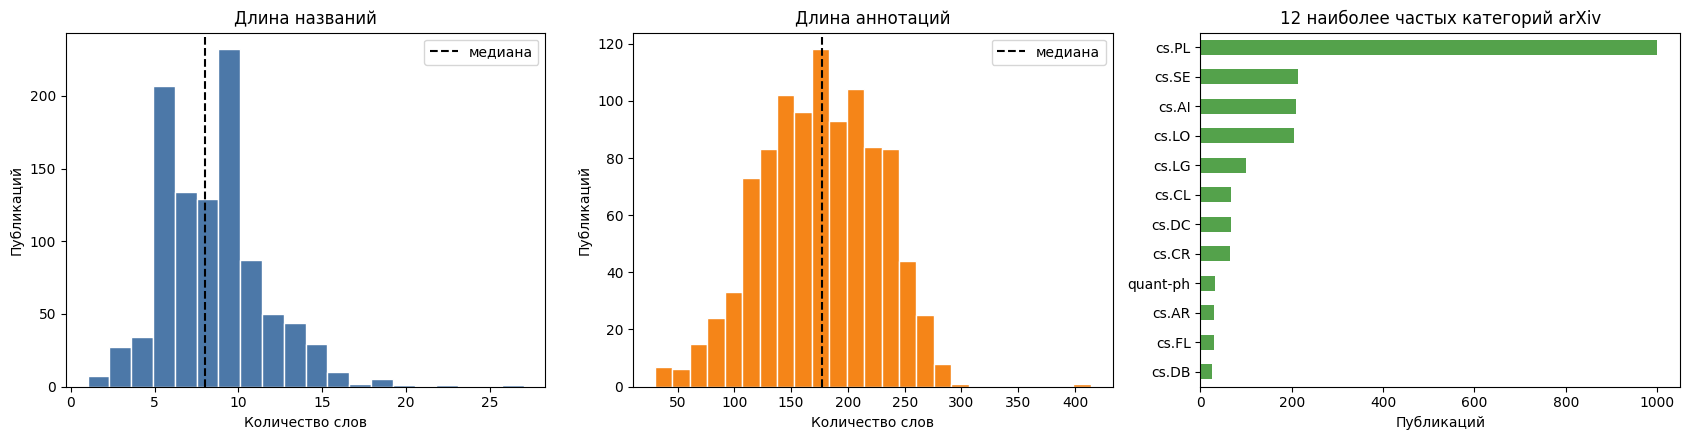

In [3]:
WORD_RE = r"(?u)\b[A-Za-z][A-Za-z'-]+\b"

df["text"] = df["title"].fillna("") + " " + df["abstract"].fillna("")

df["title_word_count"] = (
    df["title"].fillna("").str.findall(WORD_RE).str.len()
)
df["abstract_word_count"] = (
    df["abstract"].fillna("").str.findall(WORD_RE).str.len()
)

all_authors = [
    a.strip()
    for x in df["authors"].fillna("")
    for a in x.split(";")
    if a.strip()
]

all_categories = [
    c.strip()
    for x in df["categories"].fillna("")
    for c in x.split(";")
    if c.strip()
]

normalized_titles = (
    df["title"].fillna("").str.replace(r"\s+", " ", regex=True).str.strip().str.casefold()
)

quality_report = pd.Series(
    {
        "Публикаций": len(df),
        "Период": f"{df.published.min().date()} — {df.published.max().date()}",
        "Уникальных авторов": len(set(all_authors)),
        "Медиана слов в названии": df.title_word_count.median(),
        "Медиана слов в аннотации": df.abstract_word_count.median(),
        "Дубликатов arXiv ID": int(df["arxiv_id"].duplicated().sum()),
        "Дубликатов названий": int(normalized_titles.duplicated().sum()),
        "Пустых названий": int(df["title"].fillna("").str.strip().eq("").sum()),
        "Пустых аннотаций": int(df["abstract"].fillna("").str.strip().eq("").sum()),
        "Пустых авторов": int(df["authors"].fillna("").str.strip().eq("").sum()),
        "Пустых категорий": int(df["categories"].fillna("").str.strip().eq("").sum()),
        "Некорректных дат": int(df[["published", "updated"]].isna().any(axis=1).sum()),
    }
)
display(quality_report.to_frame("Значение"))

display(
    pd.Series(all_authors)
    .value_counts()
    .head(10)
    .rename_axis("Автор")
    .to_frame("Публикаций")
)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].hist(df.title_word_count, bins=20, color="#4C78A8", edgecolor="white")
axes[0].axvline(df.title_word_count.median(), color="black", ls="--", label="медиана")
axes[0].set(title="Длина названий", xlabel="Количество слов", ylabel="Публикаций")
axes[0].legend()

axes[1].hist(df.abstract_word_count, bins=25, color="#F58518", edgecolor="white")
axes[1].axvline(df.abstract_word_count.median(), color="black", ls="--", label="медиана")
axes[1].set(title="Длина аннотаций", xlabel="Количество слов", ylabel="Публикаций")
axes[1].legend()

(
    pd.Series(all_categories)
    .value_counts()
    .head(12)
    .sort_values()
    .plot.barh(ax=axes[2], color="#54A24B")
)
axes[2].set(title="12 наиболее частых категорий arXiv", xlabel="Публикаций", ylabel="")

plt.tight_layout()
plt.show()


Корпус содержит 1000 публикаций за период с 22 января по 1 октября 2026 года и 3057 уникальных авторов. Медианная длина названия составляет 8 слов, аннотации — 177.5 слова. Проверка качества выше отдельно учитывает пропуски, дубликаты идентификаторов и нормализованных названий, поэтому вывод не опирается только на визуальный просмотр таблицы.

Все публикации связаны с `cs.PL`, однако многие одновременно относятся к `cs.SE`, `cs.AI`, `cs.LO`, `cs.LG`, `cs.DC` и `cs.CR`. Это показывает междисциплинарность современной теории и практики языков программирования и объясняет появление в дальнейшем анализе кластеров, связанных с ИИ, логикой, распределенными системами и безопасностью.


### Проверка закона Ципфа

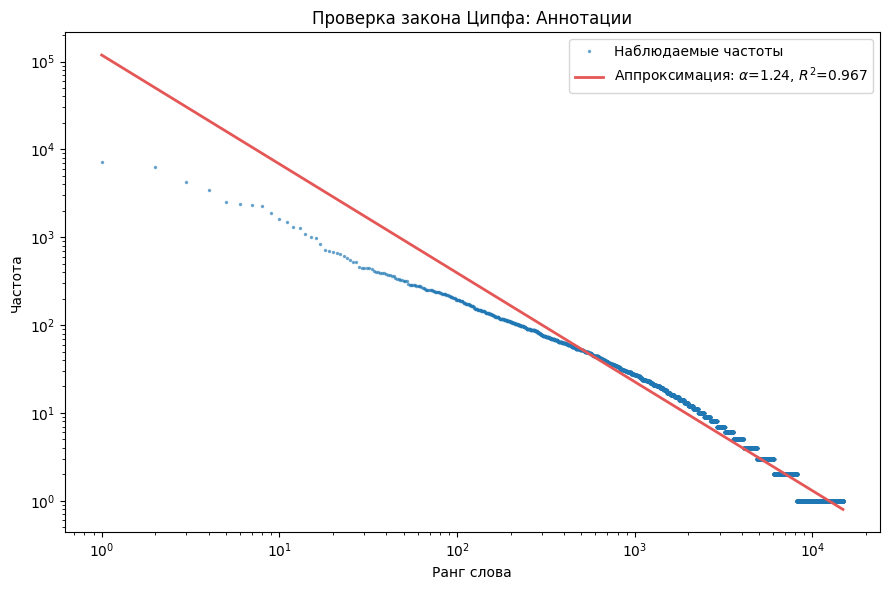

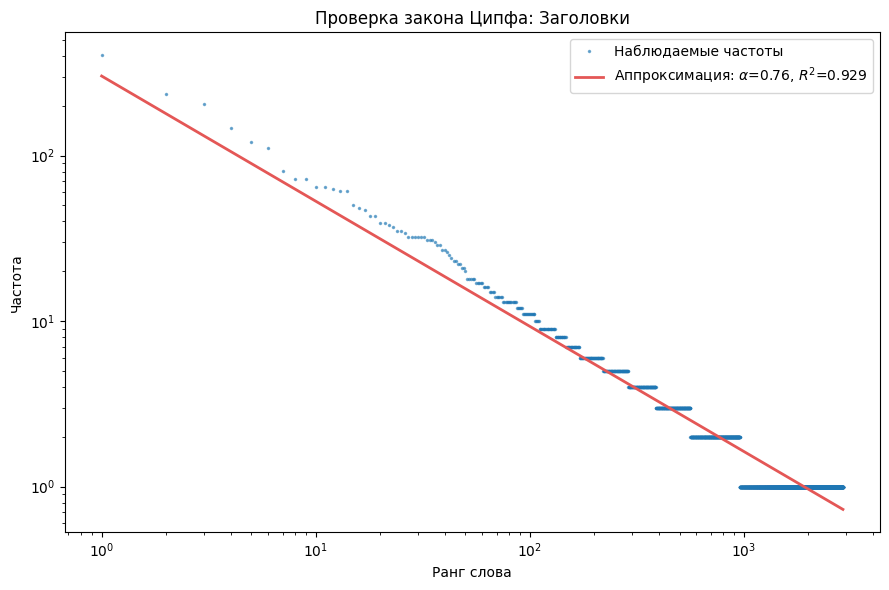

In [4]:
WORD_RE = r"(?u)\b[a-z][a-z'-]{1,}\b"

def zipf(text, title):
    raw_text = " ".join(text).lower()
    raw_tokens = re.findall(WORD_RE, raw_text)

    token_counts = Counter(raw_tokens)
    freq = np.array(sorted(token_counts.values(), reverse=True))
    ranks = np.arange(1, len(freq) + 1)

    log_ranks = np.log10(ranks)
    log_freq = np.log10(freq)

    slope, intercept = np.polyfit(log_ranks, log_freq, 1)
    alpha = -slope
    pred_log = intercept + slope * log_ranks
    ss_res = np.sum((log_freq - pred_log) ** 2)
    ss_tot = np.sum((log_freq - log_freq.mean()) ** 2)
    r_squared = 1 - ss_res / ss_tot

    fig, ax = plt.subplots(figsize=(9, 6))
    ax.loglog(ranks, freq, ".", ms=3, alpha=0.55, label="Наблюдаемые частоты")
    ax.loglog(
        ranks,
        10 ** pred_log,
        color="#E45756",
        lw=2,
        label=fr"Аппроксимация: $\alpha$={alpha:.2f}, $R^2$={r_squared:.3f}",
    )
    ax.set_xlabel("Ранг слова")
    ax.set_ylabel("Частота")
    ax.set_title(f"Проверка закона Ципфа: {title}")
    ax.legend()
    plt.tight_layout()
    plt.show()

zipf(df["abstract"].fillna(""), "Аннотации")
zipf(df["title"].fillna(""), "Заголовки")


В логарифмических координатах зависимость частоты от ранга близка к линейной: для аннотаций $R^2 \approx 0.967$, для заголовков $R^2 \approx 0.929$. Это подтверждает применимость закона Ципфа к обоим корпусам, хотя соответствие не является точным.

Для аннотаций $\alpha \approx 1.24$: частоты убывают несколько быстрее классического варианта закона с $\alpha \approx 1$.

Для коротких заголовков $\alpha \approx 0.76$, то есть распределение более пологое. Отличия особенно заметны для нескольких самых частых слов и в разреженном хвосте

### Проверка закона Хипса

Закон Хипса описывает рост словаря корпуса: $V(N) = K N^\beta$, где $N$ — число просмотренных токенов, $V(N)$ — число уникальных слов, $K$ и $\beta$ — параметры корпуса

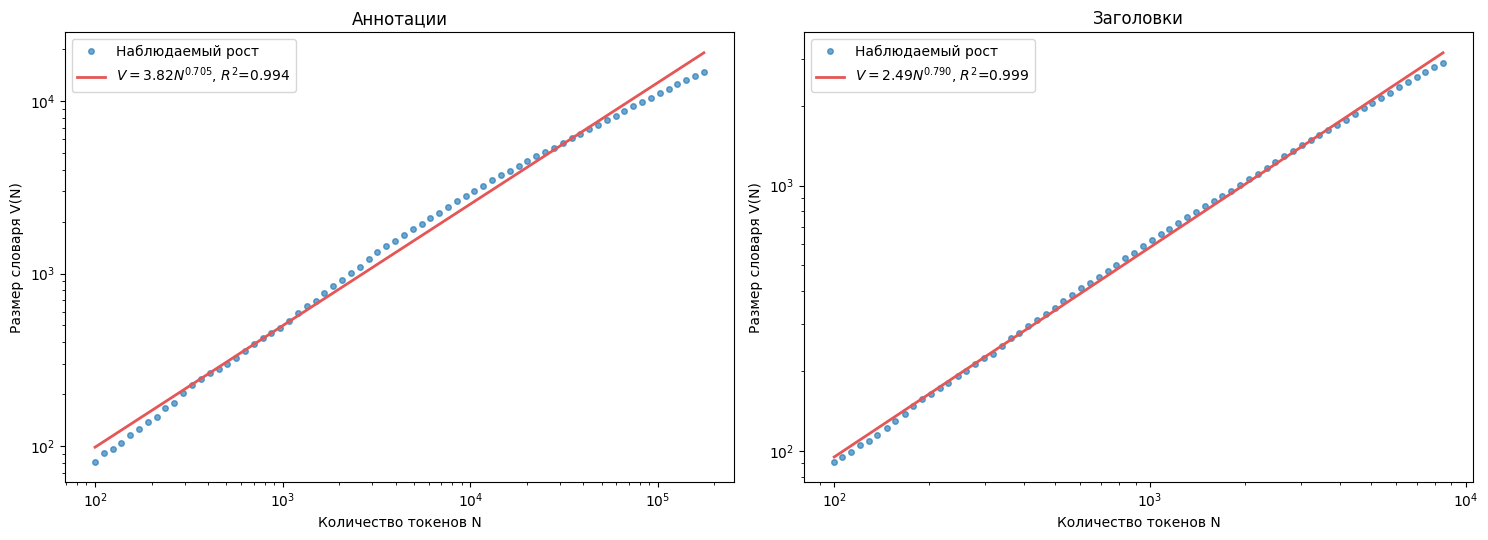

,Корпус,Токенов,Уникальных слов,K,beta,R*R
0,Аннотации,175599,14849,3.819,0.705,0.994
1,Заголовки,8478,2898,2.493,0.790,0.999


In [24]:
def heaps(texts, title, ax, points=70):
    documents = [str(text) for text in texts]
    order = np.random.default_rng(42).permutation(len(documents))
    tokens = []
    for doc_id in order:
        tokens.extend(re.findall(WORD_RE, documents[doc_id].lower()))

    checkpoints = np.unique(
        np.geomspace(100, len(tokens), num=points).astype(int)
    )
    checkpoint_set = set(checkpoints)
    vocabulary = set()
    vocabulary_sizes = []

    for token_count, token in enumerate(tokens, start=1):
        vocabulary.add(token)
        if token_count in checkpoint_set:
            vocabulary_sizes.append(len(vocabulary))

    vocabulary_sizes = np.asarray(vocabulary_sizes)
    log_n = np.log10(checkpoints)
    log_v = np.log10(vocabulary_sizes)
    beta, log_k = np.polyfit(log_n, log_v, 1)
    predicted_log_v = log_k + beta * log_n
    k = 10 ** log_k
    ss_res = np.sum((log_v - predicted_log_v) ** 2)
    ss_tot = np.sum((log_v - log_v.mean()) ** 2)
    r_squared = 1 - ss_res / ss_tot

    ax.loglog(checkpoints, vocabulary_sizes, "o", ms=4, alpha=0.65, label="Наблюдаемый рост")
    ax.loglog(
        checkpoints, 10 ** predicted_log_v, color="#E45756", lw=2,
        label=fr"$V={k:.2f}N^{{{beta:.3f}}}$, $R^2$={r_squared:.3f}",
    )
    ax.set(title=title, xlabel="Количество токенов N", ylabel="Размер словаря V(N)")
    ax.legend()

    return {
        "Корпус": title, "Токенов": len(tokens), "Уникальных слов": len(vocabulary),
        "K": k, "beta": beta, "R*R": r_squared,
    }

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
abstract_heaps = heaps(df["abstract"].fillna(""), "Аннотации", axes[0])
title_heaps = heaps(df["title"].fillna(""), "Заголовки", axes[1])
plt.tight_layout()
plt.show()

heaps_results = pd.DataFrame([abstract_heaps, title_heaps])
display(heaps_results.round({"K": 3, "beta": 3, "R*R": 3}))

### Интерпретация закона Хипса

Для аннотаций получено $V(N) \approx 3.82N^{0.705}$ при $R^2 \approx 0.994$, для заголовков - $V(N) \approx 2.49N^{0.790}$ при $R^2 \approx 0.999$. В обоих случаях зависимость в логарифмических координатах почти линейна, а показатель $0 < \beta < 1$, поэтому рост словаря хорошо соответствует закону Хипса.

## Ключевые слова публикаций

In [6]:
from nltk.stem.snowball import SnowballStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer

stemmer = SnowballStemmer("english")

CUSTOM_STOP = set(ENGLISH_STOP_WORDS)
STOP_STEMS = {stemmer.stem(word) for word in CUSTOM_STOP}

def normalized_tokens(text):
    text = unicodedata.normalize("NFKC", str(text)).lower()
    text = text.replace("–", "-").replace("—", "-")
    tokens = re.findall(r"(?u)\b[a-z][a-z-]{2,}\b", text.lower())
    
    result = []
    for token in tokens:
        if token in CUSTOM_STOP:
            continue
        stem = stemmer.stem(token)
        if stem not in STOP_STEMS:
            result.append(stem)
    
    return result

vectorizer = TfidfVectorizer(
    tokenizer=normalized_tokens,
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 3),
    min_df=2,
    max_df=0.75,
    sublinear_tf=True,
    max_features=5000,
    norm="l2"
)

tfidf = vectorizer.fit_transform(df["text"])
terms = vectorizer.get_feature_names_out()

def row_top_terms(row_idx, k=10):
    row = tfidf.getrow(row_idx)
    
    sorted_indices = np.argsort(row.data)[::-1][:k]
    top_term_indices = row.indices[sorted_indices]
    
    return tuple(terms[top_term_indices])

df["keywords"] = [row_top_terms(i) for i in range(len(df))]

all_keywords = [keyword for kws in df["keywords"] for keyword in set(kws)]
keyword_counts = Counter(all_keywords)

display(df[["title", "keywords"]].head(10))

top_keywords_df = pd.DataFrame(
    keyword_counts.most_common(25),
    columns=["Ключевое слово", "Публикаций"]
)
display(top_keywords_df)

,title,keywords
0,Augmenting Rewrite Rule Sets via Knuth-Bendix ...,"(eqsat, rewrit rule, rule set, rewrit, augment..."
1,Associativity and Commutativity in Equality Sa...,"(equal satur, satur, equal, commut, associ, mu..."
2,Fixing the Fixpoint: A Formal Theory of Conver...,"(fixpoint, converg, detector, increment, forma..."
3,Automatically Building Machine-Checked Assuran...,"(intend, specif proof, assur, codebas, review,..."
4,Freely Generated Categorical Structures and Au...,"(categor structur, thesi, phd, categor, introd..."
5,From Verification Failures to Reusable Guidanc...,"(packag, kit, audit, guidanc, clean, defect, c..."
6,"Vosti: Specifying, Implementing, and Verifying...","(logit, kv-cach, llm infer, mode, vllm, page, ..."
7,The Mode of Null-A: Compositional Computation ...,"(mathbf, affin, jacobian, matric, ast, invers,..."
8,Automated Prefetching for Object Spatial Progr...,"(travers, plan, object, graph, request, tempor..."
9,Formal Reasoning about Performance Models,"(proof rule, sound complet proof, almost-sur, ..."


,Ключевое слово,Публикаций
0,agent,47
1,quantum,42
2,probabilist,27
3,contract,26
4,rust,26
5,type,25
6,proof,23
7,kernel,23
8,translat,22
9,llms,21


## Граф связей ключевых слов

Вершин: 214, ребер: 337
Компонент связности: 7, размеры: [202, 2, 2, 2, 2, 2, 2]
Доля вершин в крупнейшей компоненте: 94.4%


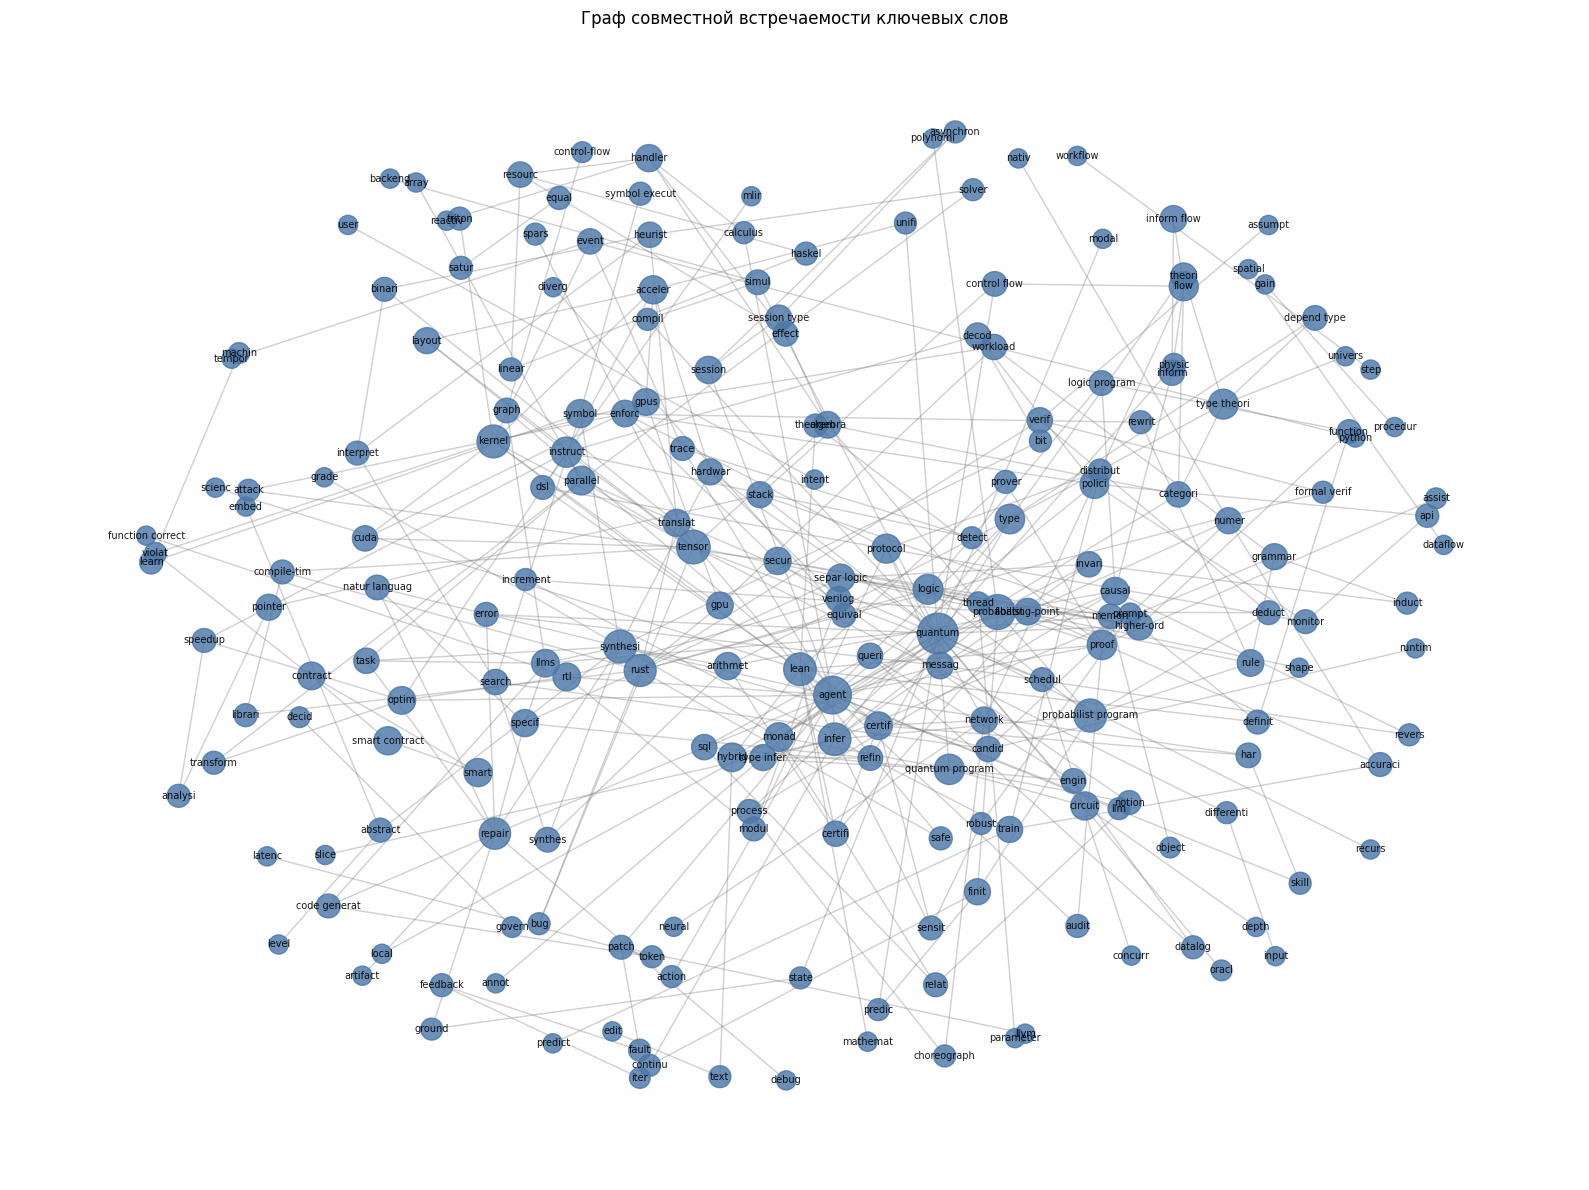

In [7]:
kept = [k for k, _ in keyword_counts.most_common(250)]
kept_set = set(kept)

keyword_edges = Counter()
for kws in df["keywords"]:
    pairs = itertools.combinations(sorted(set(kws) & kept_set), 2)
    keyword_edges.update(pairs)

Gk = nx.Graph()

for k in kept:
    Gk.add_node(k, document_frequency=keyword_counts[k])

MIN_EDGE_WEIGHT = 2
for (u, v), w in keyword_edges.items():
    if w >= MIN_EDGE_WEIGHT:
        Gk.add_edge(u, v, weight=w, distance=1 / w)

Gk.remove_nodes_from(list(nx.isolates(Gk)))

components = sorted(nx.connected_components(Gk), key=len, reverse=True)
component_sizes = [len(component) for component in components]
largest_component = Gk.subgraph(components[0]).copy()

print(f"Вершин: {Gk.number_of_nodes()}, ребер: {Gk.number_of_edges()}")
print(f"Компонент связности: {len(components)}, размеры: {component_sizes}")
print(f"Доля вершин в крупнейшей компоненте: {len(components[0]) / Gk.number_of_nodes():.1%}")

weighted_degree = dict(Gk.degree(weight="weight"))
draw_nodes = sorted(Gk, key=weighted_degree.get, reverse=True)

H = Gk.subgraph(draw_nodes).copy()

pos = nx.spring_layout(H, weight="weight", seed=42, k=0.65)

node_sizes = [50 + 100 * math.sqrt(weighted_degree[n]) for n in H]

fig, ax = plt.subplots(figsize=(16, 12))

nx.draw_networkx_edges(
    H, pos,
    alpha=0.35,
    edge_color="#777777",
    ax=ax,
)

nx.draw_networkx_nodes(
    H, pos,
    node_size=node_sizes,
    node_color="#4C78A8",
    alpha=0.82,
    ax=ax,
)

label_nodes = sorted(H, key=weighted_degree.get, reverse=True)
labels = {n: n for n in label_nodes}
nx.draw_networkx_labels(H, pos, labels=labels, font_size=7, alpha=0.9, ax=ax)

ax.set_title("Граф совместной встречаемости ключевых слов")
ax.axis("off")
plt.tight_layout()
plt.show()

## Кластеризация

Всего кластеров: 20, взвешенная модулярность Q = 0.729


,Кластер,Размер,Характерные термины
0,1,29,"synthesi, repair, symbol, llms, arithmet, spec..."
1,2,23,"probabilist, probabilist program, infer, logic..."
2,3,23,"tensor, kernel, instruct, parallel, acceler, g..."
3,4,20,"agent, optim, rtl, pointer, verilog, har, spee..."
4,5,20,"quantum, quantum program, hybrid, circuit, sta..."
5,6,18,"protocol, polici, secur, network, enforc, trai..."
6,7,15,"rust, translat, heurist, verif, compile-tim, i..."
7,8,15,"lean, proof, certif, graph, sensit, dsl, theor..."
8,9,10,"handler, algebra, resourc, effect, haskel, lin..."
9,10,9,"monad, queri, sql, engin, relat, notion, datal..."


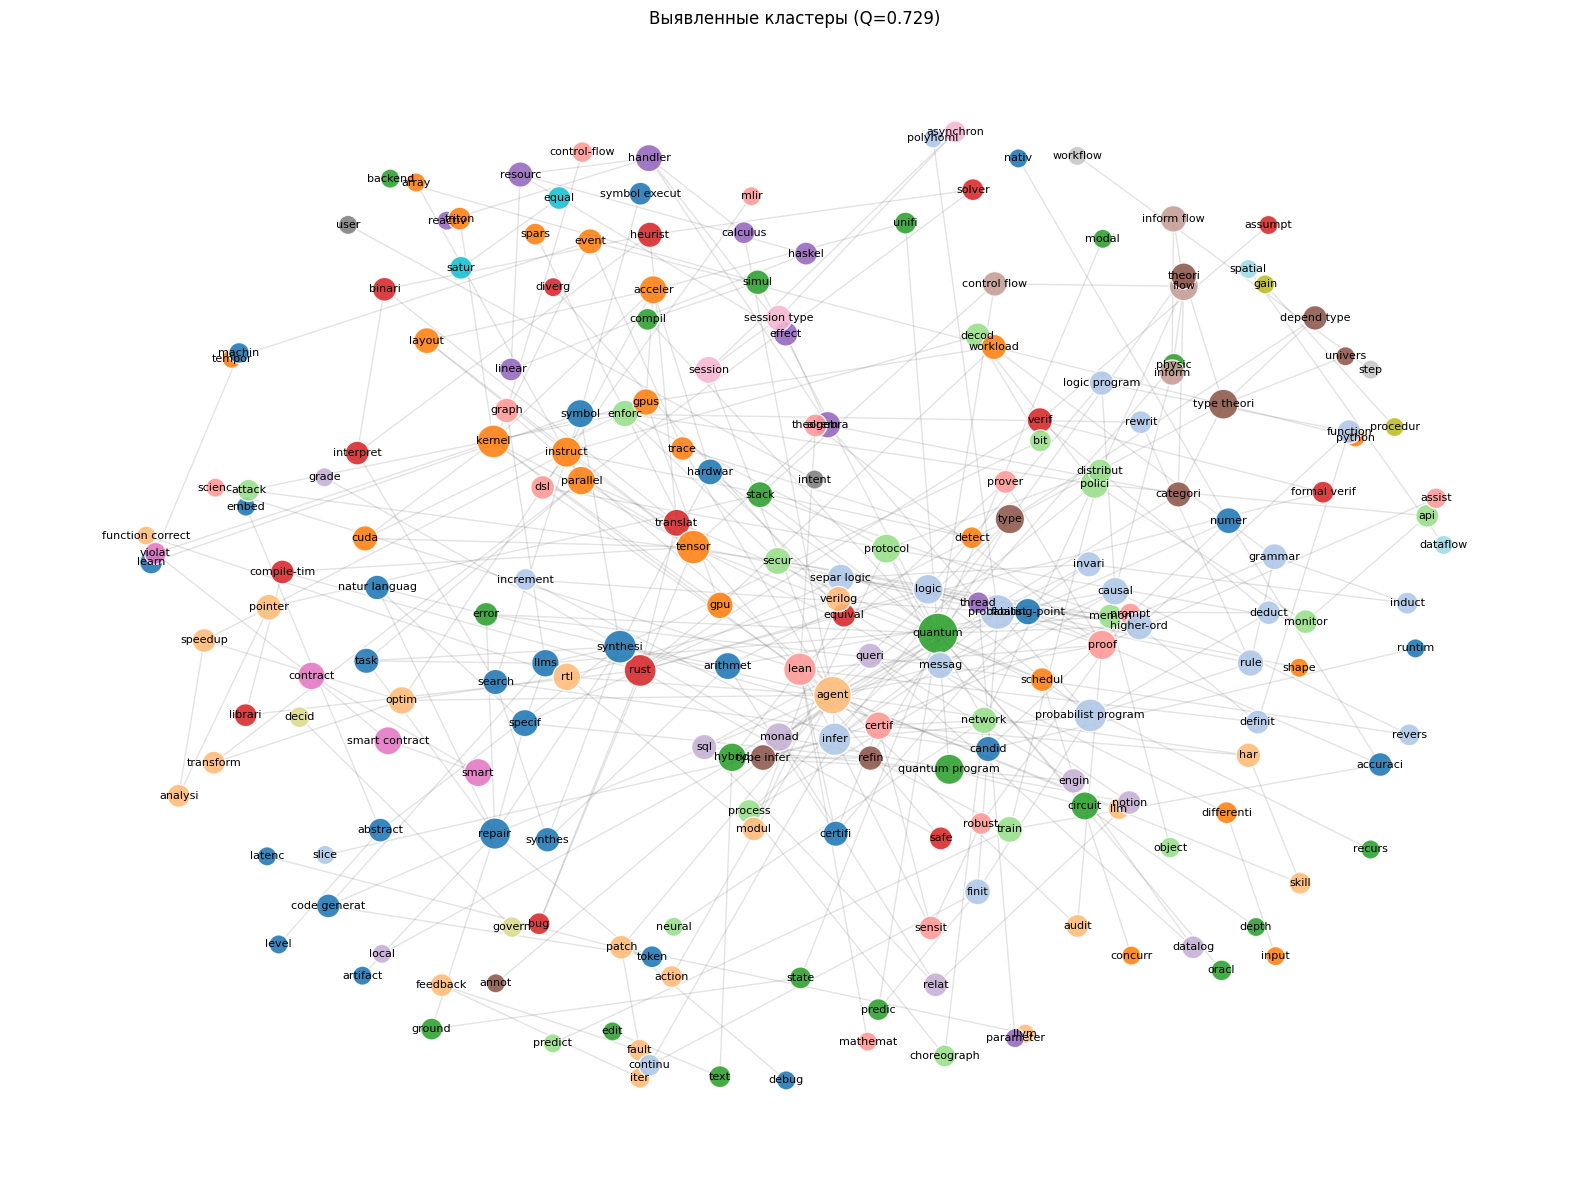

In [8]:
communities = list(
    nx.community.greedy_modularity_communities(Gk, weight="weight")
)
modularity = nx.community.modularity(Gk, communities, weight="weight")

print(f"Всего кластеров: {len(communities)}, взвешенная модулярность Q = {modularity:.3f}")

community_of = {
    node: cluster_id
    for cluster_id, community in enumerate(communities, 1)
    for node in community
}
nx.set_node_attributes(Gk, community_of, "community")

TOP_TERMS_PER_CLUSTER = 12

rows = []
for cluster_id, community in enumerate(communities, 1):
    top_terms = sorted(
        community,
        key=lambda n: weighted_degree[n],
        reverse=True,
    )[:TOP_TERMS_PER_CLUSTER]

    rows.append({
        "Кластер": cluster_id,
        "Размер": len(community),
        "Характерные термины": ", ".join(top_terms),
    })

cluster_table = (
    pd.DataFrame(rows)
    .sort_values("Размер", ascending=False)
    .reset_index(drop=True)
)
display(cluster_table)

fig, ax = plt.subplots(figsize=(16, 12))

nx.draw_networkx_edges(
    H, pos,
    alpha=0.18,
    edge_color="#666666",
    ax=ax,
)

node_colors = [community_of[n] for n in H]
nx.draw_networkx_nodes(
    H, pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap="tab20",
    alpha=0.88,
    edgecolors="white",
    ax=ax,
)

nx.draw_networkx_labels(
    H, pos,
    labels=labels,
    font_size=8,
    ax=ax,
)

ax.set_title(f"Выявленные кластеры (Q={modularity:.3f})")
ax.axis("off")
plt.tight_layout()
plt.show()

### Интерпретация

Алгоритм объединяет термины, которые регулярно встречаются в одних публикациях. Полученная взвешенная модулярность $Q \approx 0.73$ близка к единице, поэтому разделение на тематические сообщества выражено хорошо

Крупнейшие сообщества имеют понятную предметную структуру:

1. Синтез и автоматизированная верификация программ: `synthesi`, `repair`, `symbol`, `certif`, `specif`, `llms`.
2. Вероятностное программирование: `probabilist`, `infer`, `probabilist program`, `logic`.
3. Высокопроизводительные вычисления и компиляторы: `tensor`, `kernel`, `parallel`, `acceler`, `instruct`.
4. Агенты и проектирование аппаратуры: `agent`, `rtl`, `optim`, `verilog`, `pointer`.
5. Квантовое программирование: `quantum`, `quantum program`, `hybrid`, `circuit`.
6. Протоколы и безопасность: `protocol`, `polici`, `secur`, `enforc`, `network`.
7. Rust и формальная верификация: `rust`, `translat`, `verif`, `compile-tim`.

Средние сообщества отражают Lean и другие средства доказательства, алгебраические эффекты и Haskell, базы данных и SQL, а также теорию типов. Малые кластеры описывают узкие устойчивые сочетания, например информационные потоки, смарт-контракты, session types и equality saturation.

Таким образом, кластеры соответствуют не случайным наборам слов, а основным направлениям внутри `cs.PL`. Пересечения между направлениями отражаются центральными терминами-мостами, что дополнительно исследуется ниже.

## Центральности ключевых слов

Топ 10 узлов по метрике: DEGREE


,degree,weighted_degree,cluster
agent,0.094527,47,4
quantum,0.094527,65,5
tensor,0.059701,29,3
synthesi,0.059701,26,1
probabilist,0.054726,34,2
lean,0.054726,25,8
infer,0.054726,25,2
repair,0.049751,21,1
rust,0.044776,23,7
kernel,0.044776,26,3


Топ 10 узлов по метрике: BETWEENNESS


,betweenness,weighted_degree,cluster
agent,0.396531,47,4
quantum,0.204992,65,5
kernel,0.166177,26,3
synthesi,0.155770,26,1
infer,0.129441,25,2
tensor,0.116631,29,3
monad,0.105744,14,10
rust,0.095770,23,7
lean,0.084258,25,8
repair,0.077987,21,1


Топ 10 узлов по метрике: CLOSENESS


,closeness,weighted_degree,cluster
agent,0.778900,47,4
repair,0.687265,21,1
synthesi,0.686171,26,1
infer,0.665780,25,2
polici,0.660907,14,6
proof,0.660472,16,8
kernel,0.657335,26,3
hardwar,0.655126,9,1
llm,0.652478,4,4
action,0.652478,4,4


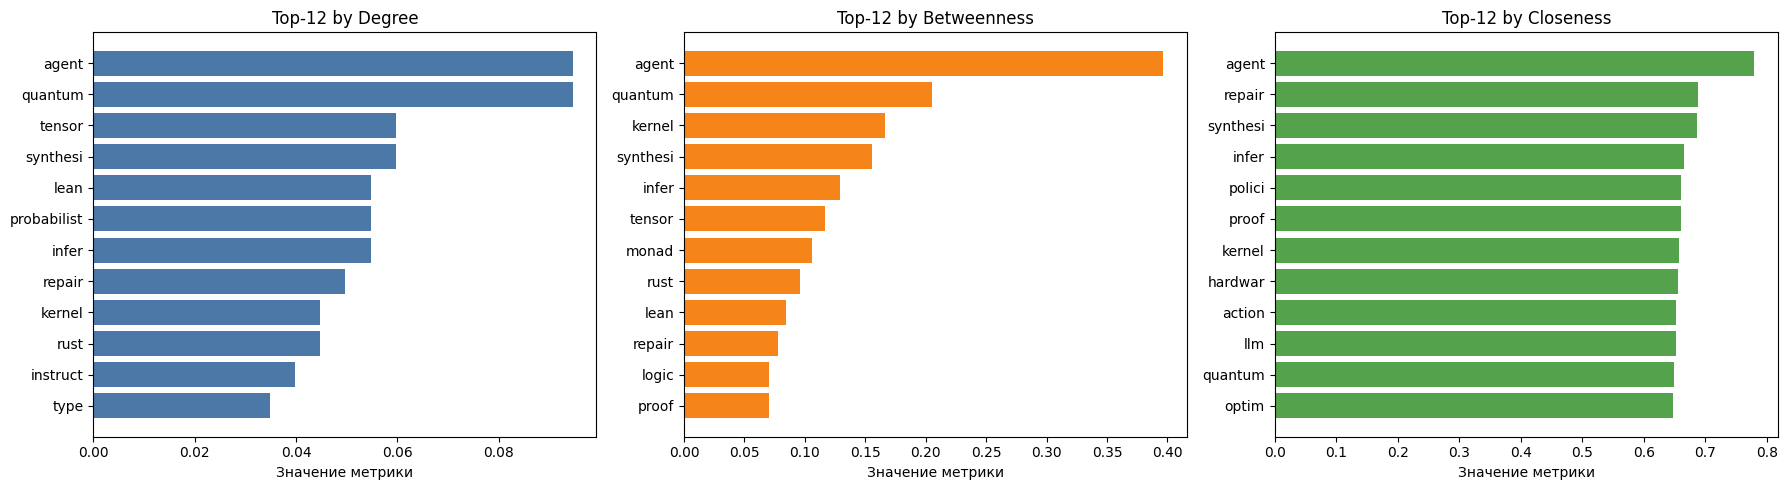

In [9]:
centrality_graph = largest_component
centrality_weighted_degree = dict(centrality_graph.degree(weight="weight"))

degree_c = nx.degree_centrality(centrality_graph)
betweenness_c = nx.betweenness_centrality(
    centrality_graph,
    weight="distance",
    normalized=True,
)
closeness_c = nx.closeness_centrality(
    centrality_graph,
    distance="distance",
)

centrality = pd.DataFrame(
    {
        "degree": pd.Series(degree_c),
        "betweenness": pd.Series(betweenness_c),
        "closeness": pd.Series(closeness_c),
        "weighted_degree": pd.Series(centrality_weighted_degree),
        "cluster": pd.Series({n: community_of[n] for n in centrality_graph}).astype(int),
    }
)

metrics = ["degree", "betweenness", "closeness"]

for metric in metrics:
    print(f"Топ 10 узлов по метрике: {metric.upper()}")
    display(
        centrality.nlargest(10, metric)[
            [metric, "weighted_degree", "cluster"]
        ]
    )

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ["#4C78A8", "#F58518", "#54A24B"]

for ax, metric, color in zip(axes, metrics, colors):
    data = centrality.nlargest(12, metric).sort_values(metric)
    ax.barh(data.index, data[metric], color=color)
    ax.set_title(f"Top-12 by {metric.replace('_', ' ').title()}", fontsize=12)
    ax.set_xlabel("Значение метрики")

plt.tight_layout()
plt.show()


### Интерпретация

Все метрики рассчитаны на крупнейшей компоненте связности графа, чтобы значения closeness и betweenness для разных компонент не сравнивались напрямую.

- Degree centrality показывает, со сколькими другими терминами связан узел. Лидируют `agent` и `quantum`; высокие позиции `synthesi`, `tensor`, `infer` и `lean` соответствуют крупным направлениям корпуса.
- Betweenness centrality показывает, как часто термин лежит на кратчайших путях. `agent`, `synthesi`, `kernel`, `infer` и `rust` выступают мостами между тематическими областями.
- Closeness centrality показывает, насколько близко термин расположен к остальным узлам. Высокие позиции `agent`, `repair`, `synthesi` и `infer` означают, что через них можно быстро перейти к разным областям графа.


## Граф публикаций

Вершин (статей): 1000
Ребер (связей): 21006
Плотность графа: 0.0421


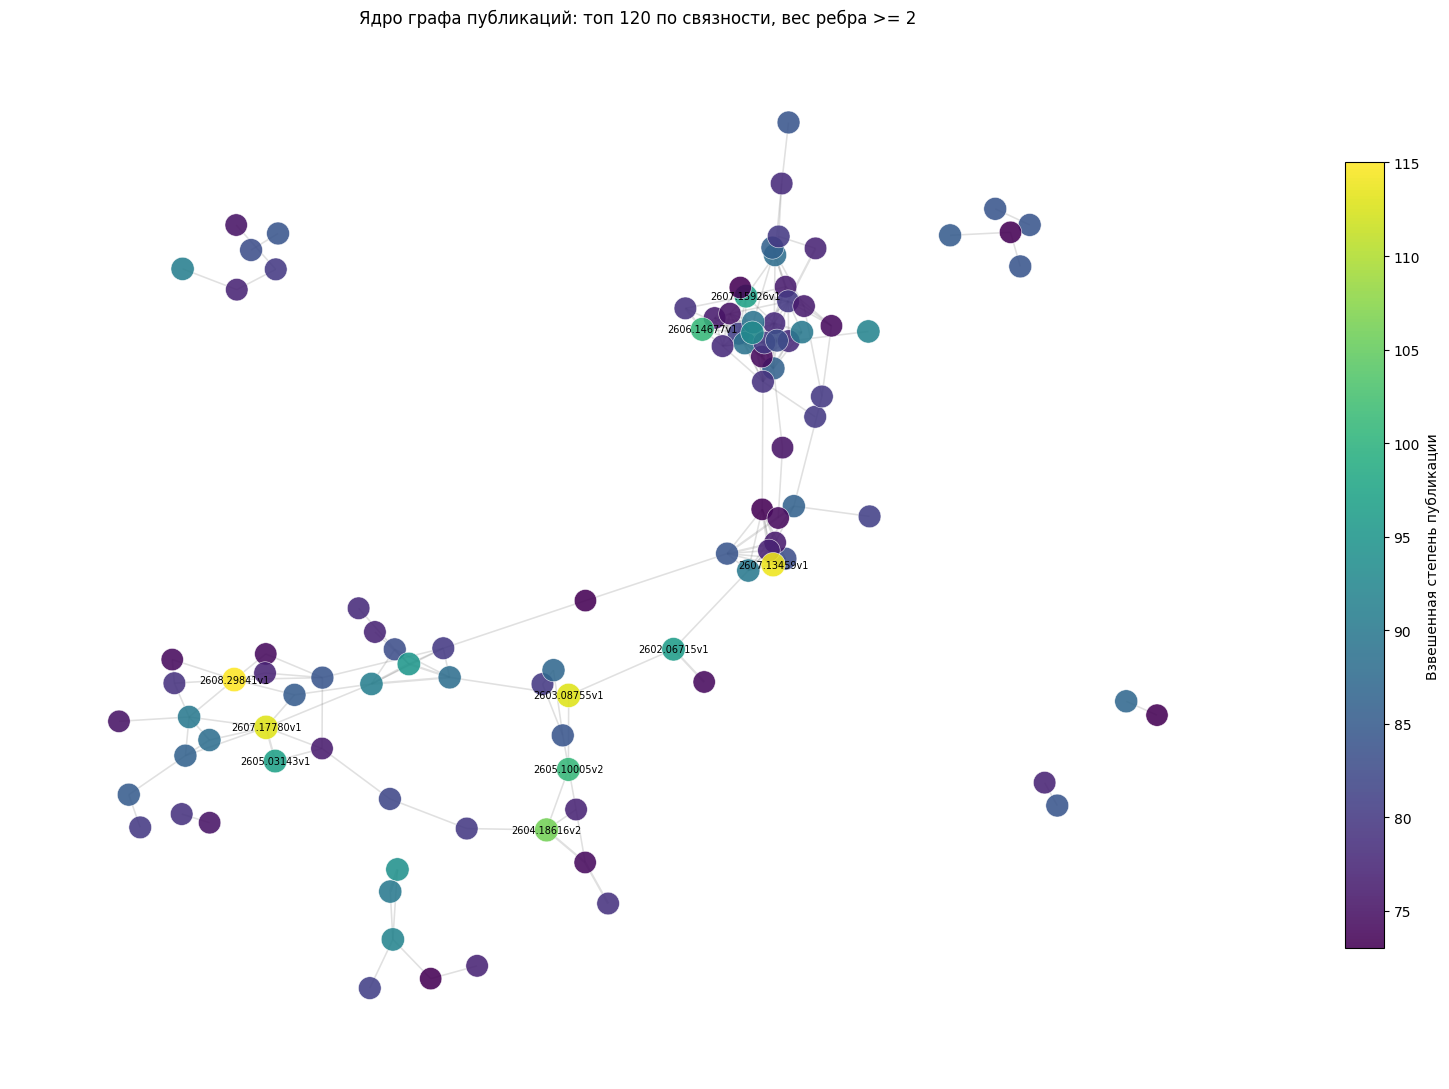

In [10]:
from collections import defaultdict

papers_by_keyword = defaultdict(list)
for i, kws in enumerate(df["keywords"]):
    for k in set(kws):
        papers_by_keyword[k].append(i)

paper_edges = Counter()
for ids in papers_by_keyword.values():
    if len(ids) > 1:
        paper_edges.update(itertools.combinations(sorted(ids), 2))

Gp = nx.Graph()

for i, row in df.iterrows():
    Gp.add_node(
        i,
        title=row.title,
        arxiv_id=row.arxiv_id,
        year=int(row.year)
    )

for (u, v), w in paper_edges.items():
    Gp.add_edge(u, v, weight=w, distance=1 / w)

print(f"Вершин (статей): {Gp.number_of_nodes()}")
print(f"Ребер (связей): {Gp.number_of_edges()}")
print(f"Плотность графа: {nx.density(Gp):.4f}")

paper_weighted_degree = dict(Gp.degree(weight="weight"))
view_nodes = sorted(Gp, key=paper_weighted_degree.get, reverse=True)[:120]
Gp_view = nx.Graph(Gp.subgraph(view_nodes))
Gp_view.remove_edges_from([
    (u, v) for u, v, data in Gp_view.edges(data=True)
    if data["weight"] < 2
])
Gp_view.remove_nodes_from(list(nx.isolates(Gp_view)))

pos_papers = nx.spring_layout(Gp_view, weight="weight", seed=42, k=0.32, iterations=100)
node_values = [paper_weighted_degree[n] for n in Gp_view]
node_sizes = [70 + 22 * math.sqrt(paper_weighted_degree[n]) for n in Gp_view]
edge_widths = [0.25 + 0.45 * Gp_view[u][v]["weight"] for u, v in Gp_view.edges()]

fig, ax = plt.subplots(figsize=(16, 11))
nx.draw_networkx_edges(Gp_view, pos_papers, width=edge_widths, alpha=0.20, edge_color="#666666", ax=ax)
nodes = nx.draw_networkx_nodes(
    Gp_view, pos_papers, node_size=node_sizes, node_color=node_values,
    cmap="viridis", alpha=0.88, linewidths=0.4, edgecolors="white", ax=ax
)
label_nodes = sorted(Gp_view, key=paper_weighted_degree.get, reverse=True)[:10]
paper_labels = {n: df.at[n, "arxiv_id"] for n in label_nodes}
nx.draw_networkx_labels(Gp_view, pos_papers, labels=paper_labels, font_size=7, ax=ax)
fig.colorbar(nodes, ax=ax, shrink=0.75, label="Взвешенная степень публикации")
ax.set_title("Ядро графа публикаций: топ 120 по связности, вес ребра >= 2")
ax.axis("off")
plt.tight_layout()
plt.show()

## Поиск публикаций

Функция `search_publications` выполняет свободный поиск публикаций. Сначала отбираются кандидаты булевыми операторами и BM25. Затем 5 лучших BM25 документов становятся стартовыми вершинами персонализированного PageRank.

Функция `recommend_similar` возвращает публикации, похожие на заданную. Вся начальная вероятность помещается в заданную публикацию. Затем PageRank распространяет ее по сильным ребрам и ранжирует статьи с учетом прямых и косвенных связей в графе.

In [11]:
import numpy as np
import pandas as pd
from collections import defaultdict
from rank_bm25 import BM25Okapi

corpus_tokens = [normalized_tokens(text) for text in df["text"]]

bm25_model = BM25Okapi(corpus_tokens, k1=1.2, b=0.75)

term_to_docs = defaultdict(set)
for doc_id, tokens in enumerate(corpus_tokens):
    unique_tokens = set(tokens)
    for token in unique_tokens:
        term_to_docs[token].add(doc_id)

all_vocabulary = list(term_to_docs.keys())
SEARCH_COLUMNS = ["score", "bm25", "graph_score", "matched_terms", "arxiv_id", "year", "title"]

def normalize_scores(values):
    values = np.asarray(values, dtype=float)
    if values.size == 0:
        return values
    max_value = values.max()
    return values / max_value if max_value > 0 else np.zeros_like(values)

def parse_query_structure(query_str):
    q = query_str.lower().strip()
    q = re.sub(r'\s+', ' ', q)
    
    and_groups = re.split(r'\band\b', q)
    
    parsed_groups = []
    for group in and_groups:
        group = group.strip()
        if not group:
            continue
        
        or_terms = re.split(r'\bor\b', group)
        
        clean_terms = [t.strip() for t in or_terms if t.strip()]
        
        if clean_terms:
            tokenized_terms = []
            for term in clean_terms:
                tokens = normalized_tokens(term) 
                tokenized_terms.extend(tokens)
            
            if tokenized_terms:
                parsed_groups.append(list(set(tokenized_terms)))
                
    return parsed_groups

def get_candidates_from_groups(parsed_groups):
    if not parsed_groups:
        return np.array([], dtype=int)
    
    first_group = parsed_groups[0]
    candidate_sets = []
    for term in first_group:
        if term in term_to_docs:
            candidate_sets.append(term_to_docs[term])
    
    if not candidate_sets:
        return np.array([], dtype=int)
        
    current_result = set.union(*candidate_sets)
    
    for group in parsed_groups[1:]:
        group_sets = []
        for term in group:
            if term in term_to_docs:
                group_sets.append(term_to_docs[term])
        
        if not group_sets:
            return np.array([], dtype=int)
            
        group_union = set.union(*group_sets)
        
        current_result &= group_union
        
        if not current_result:
            break
            
    return np.array(list(current_result), dtype=int)

def search_publications(text_query, top_n=10, seed_count=5):
    parsed_groups = parse_query_structure(text_query)
    if not parsed_groups:
        return pd.DataFrame(columns=SEARCH_COLUMNS)

    candidate_ids = get_candidates_from_groups(parsed_groups)
    if len(candidate_ids) == 0:
        return pd.DataFrame(columns=SEARCH_COLUMNS)

    unique_query_terms = sorted({term for group in parsed_groups for term in group})
    all_bm25_scores = bm25_model.get_scores(unique_query_terms)
    candidate_bm25 = all_bm25_scores[candidate_ids]

    positive_mask = candidate_bm25 > 0
    candidate_ids = candidate_ids[positive_mask]
    candidate_bm25 = candidate_bm25[positive_mask]
    if len(candidate_ids) == 0:
        return pd.DataFrame(columns=SEARCH_COLUMNS)

    seed_order = np.argsort(-candidate_bm25)[:seed_count]
    seed_ids = candidate_ids[seed_order]
    seed_scores = candidate_bm25[seed_order]
    seed_sum = seed_scores.sum()
    personalization = {
        int(doc_id): float(score / seed_sum)
        for doc_id, score in zip(seed_ids, seed_scores)
    }

    pagerank = nx.pagerank(
        Gp, alpha=0.85, personalization=personalization, weight="weight"
    )
    candidate_graph = np.array([pagerank[int(doc_id)] for doc_id in candidate_ids])

    bm25_norm = normalize_scores(candidate_bm25)
    graph_norm = normalize_scores(candidate_graph)
    final_scores = 0.70 * bm25_norm + 0.30 * graph_norm

    top_order = np.argsort(-final_scores)[:top_n]
    top_doc_ids = candidate_ids[top_order]
    result_df = pd.DataFrame({
        "doc_id": top_doc_ids,
        "score": final_scores[top_order],
        "bm25": candidate_bm25[top_order],
        "graph_score": graph_norm[top_order],
        "matched_terms": [
            ", ".join(term for term in unique_query_terms if term in set(corpus_tokens[doc_id]))
            for doc_id in top_doc_ids
        ],
    })

    result_df = result_df.set_index("doc_id").join(df[["arxiv_id", "year", "title"]])
    return result_df[SEARCH_COLUMNS]

def resolve_paper(query):
    query = str(query).strip().casefold()
    if not query:
        return None

    exact_id = df.index[df["arxiv_id"].str.casefold().eq(query)].tolist()
    if exact_id:
        return exact_id[0]

    title_fragment = df.index[df["title"].str.casefold().str.contains(re.escape(query), na=False)].tolist()
    return title_fragment[0] if title_fragment else None

def recommend_similar(query, top_n=10):
    source_doc_id = resolve_paper(query)
    if source_doc_id is None:
        return pd.DataFrame(columns=["pagerank", "graph_distance", "common_tags", "shared_keywords", "arxiv_id", "year", "title"])

    pagerank = nx.pagerank(
        Gp, alpha=0.85, personalization={source_doc_id: 1.0}, weight="weight"
    )
    pagerank.pop(source_doc_id, None)
    top_doc_ids = [doc_id for doc_id, _ in sorted(
        pagerank.items(), key=lambda item: item[1], reverse=True
    )[:top_n]]

    distances = nx.single_source_shortest_path_length(Gp, source_doc_id)
    source_keywords = set(df.at[source_doc_id, "keywords"])
    shared_keywords = [
        sorted(source_keywords & set(df.at[doc_id, "keywords"]))
        for doc_id in top_doc_ids
    ]

    result = df.loc[top_doc_ids, ["arxiv_id", "year", "title"]].copy()
    result.insert(0, "shared_keywords", [", ".join(words[:5]) for words in shared_keywords])
    result.insert(0, "common_tags", [len(words) for words in shared_keywords])
    result.insert(0, "graph_distance", [distances.get(doc_id, np.inf) for doc_id in top_doc_ids])
    result.insert(0, "pagerank", [pagerank[doc_id] for doc_id in top_doc_ids])
    result.index.name = "doc_id"
    return result

## Проверка поиска


In [12]:
print("Проверка на получение похожих публикаций")
display(recommend_similar("2607.03951v2", top_n=5).round(4))

print("Проверка на получение результатов свободного поиска с оператором OR")
free_search = search_publications("rust or framework", top_n=5)
display(free_search.round(4))

print("Проверка на получение результатов свободного поиска с оператором AND")
and_search = search_publications("formal and verification and rust", top_n=5)
display(and_search.round(4))


Проверка на получение похожих публикаций


,pagerank,graph_distance,common_tags,shared_keywords,arxiv_id,year,title
doc_id,,,,,,,
359,0.0102,1,3,"python, statist, statist method",2608.16911v2,2026,r2py: AI-Assisted Conversion of R Statistical ...
793,0.0093,1,3,"hypothesi, hypothesi test, statist",2603.28274v1,2026,"Statistics 101, 201, and 202: Three Shiny Apps..."
60,0.0071,1,2,"statist, statist method",2609.20037v1,2026,How Often Does Your Program Fail?
19,0.0068,1,2,"assumpt, verif",2609.34886v1,2026,Fewer Assumptions by Design: A Reusable Skill ...
633,0.0066,1,2,"formal verif, verif",2605.04377v1,2026,Towards Formal Verification of Hybrid Synchron...


Проверка на получение результатов свободного поиска с оператором OR


,score,bm25,graph_score,matched_terms,arxiv_id,year,title
doc_id,,,,,,,
151,0.9997,5.9538,0.9989,"framework, rust",2608.22624v1,2026,Rust for Secure Backend Development: A Critica...
106,0.9808,5.7901,1.0000,"framework, rust",2609.04372v1,2026,Corten - Foundational Verification of Rust Pro...
195,0.9435,5.5614,0.9654,"framework, rust",2608.13759v1,2026,"GPU Offload in Rust: Portable, Safe, and Fast"
88,0.9089,5.3439,0.9355,"framework, rust",2609.09641v1,2026,UnsafeChecker: Finding Soundness Bugs in Rust ...
792,0.9037,5.3431,0.9182,rust,2603.28326v1,2026,Towards verifying unsafe Rust programs against...


Проверка на получение результатов свободного поиска с оператором AND


,score,bm25,graph_score,matched_terms,arxiv_id,year,title
doc_id,,,,,,,
340,1.0000,7.1949,1.0000,"formal, rust, verif",2607.12282v1,2026,Verifying Probabilistic Programs in Rust
664,0.9077,6.7270,0.8440,"formal, rust, verif",2605.00034v1,2026,Symbolic Execution Meets Multi-LLM Orchestrati...
150,0.8684,6.3274,0.8426,"formal, rust, verif",2608.22630v1,2026,VeGo: Direct Deductive Formal Verification of ...
546,0.8051,5.9098,0.7670,"formal, rust, verif",2605.26457v1,2026,Verus-SpecGym: An Agentic Environment for Eval...
